# BUSI2066 Group K: Adidas Footwear Growth & Purchase Drivers
**Python analysis notebook** (supports the final report)

Business question: should adidas put its next footwear budget into **(a)** cross-selling shoes to apparel buyers or **(b)** design/comfort improvements, to lift footwear sales among 18-26 year olds?

**How to use**
1. Put the raw Qualtrics export (CSV; choice text or numeric codes both work) in the same folder and set `RAW_PATH` below.
2. Run the *Column map* cell and check that every column name matches your export (edit `COL` if not).
3. Run all cells top to bottom. Figures are saved to `figs/` and the cleaned, anonymised file to `adidas_clean_anonymised.csv`.
4. Copy the printed statistics into the report's Results tables.

In [10]:
import os, warnings
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
os.makedirs("figs", exist_ok=True)
ALPHA = 0.05

def wilson(k, n, z=1.959964):
    # Wilson score 95% confidence interval for a proportion k/n -> (p, low, high)
    p = k / n
    d = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / d
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return p, centre - half, centre + half

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

## A. Load, clean and anonymise the raw Qualtrics export

In [11]:
RAW_PATH = "Group K - Adidas_November 11, 2026_14.43.csv"   # <- raw Qualtrics export
CLEAN_PATH = "adidas_clean_anonymised.csv"

# Column map: matches the Group K export (choice text for categories, numbers for scales).
COL = {
    "consent": "Survey Statement",
    "age": "Q1", "bought": "Q2", "own_app": "Q3", "own_shoe": "Q4", "brand": "Q5",
    "sneaker": ["Q6-Q10_1", "Q6-Q10_2", "Q6-Q10_3", "Q6-Q10_4", "Q6-Q10_5"],   # price, style, comfort, brand image, influencer
    "repeat": ["Q11_1", "Q11_2", "Q11_3", "Q11_4", "Q11_5"],                  # Q11 = deliberate repeat of the same five sneaker items (data-quality check)
    "attitude": ["Q12-14_1", "Q12-14_2", "Q12-14_3"],                          # 0-100 sliders
    "intent": "Q15_1",                                                          # 1-7, 0 = Cannot judge
    "gender": "Q16", "social": "Q17",
}
FACTORS = ["Price", "Style & design", "Comfort & fit", "Brand image", "Influencer approval"]

def norm(x): return str(x).strip().lower()
def cat(s, mapping):
    # map choice text (or numeric code) to a clean label; unanswered stays missing
    return s.map(lambda v: mapping.get(norm(v)) if pd.notna(v) else np.nan)
def num(s):
    # '7=Extremely important' -> 7 ; '65' -> 65 ; blank -> NaN
    return pd.to_numeric(s.astype("string").str.extract(r"^\s*(\d+(?:\.\d+)?)")[0], errors="coerce")

YESNO = {"yes": "Yes", "no": "No", "1": "Yes", "2": "No"}
CONSENT = {"i agree.": "Agree", "i do not agree.": "Disagree", "1": "Agree", "2": "Disagree"}
AGE = {"under 18": "Under 18", "18-26": "18-26", "27 or older": "27+", "1": "Under 18", "2": "18-26", "3": "27+"}
BRAND = {"nike": "Nike", "adidas": "Adidas", "puma": "Puma", "asics": "Asics", "others": "Others",
         "1": "Nike", "2": "Adidas", "4": "Puma", "5": "Asics", "6": "Others"}
GENDER = {"woman": "Woman", "man": "Man", "non-binary": "Non-binary", "prefer not to say": "Prefer not to say"}
SOCIAL = {"under 1": "Under 1h", "1-2": "1-2h", "3-4": "3-4h", "5 or more": "5h or more"}

raw = pd.read_csv(RAW_PATH, dtype=str)
# Qualtrics adds 2 extra header rows (question text, ImportId) under the column names
if "Progress" in raw.columns:
    raw = raw[pd.to_numeric(raw["Progress"], errors="coerce").notna()].copy()
n_before = len(raw)
if "Status" in raw.columns:   # drop survey previews / test responses
    raw = raw[~raw["Status"].astype(str).str.contains("Preview|Spam", case=False, na=False)].copy()
print("Rows in export:", n_before, "| survey previews/tests removed:", n_before - len(raw), "| real responses:", len(raw))

needed = [COL[k] for k in ["consent","age","bought","own_app","own_shoe","brand","intent","gender","social"]]
needed += COL["sneaker"] + COL["repeat"] + COL["attitude"]
missing = [c for c in needed if c not in raw.columns]
assert not missing, f"These columns are not in your export, edit COL: {missing}\nAvailable: {list(raw.columns)}"

Rows in export: 85 | survey previews/tests removed: 2 | real responses: 83


In [12]:
raw["consent"] = cat(raw[COL["consent"]], CONSENT)
raw["age"] = cat(raw[COL["age"]], AGE)
raw["bought"] = cat(raw[COL["bought"]], YESNO)
raw["own_apparel"] = cat(raw[COL["own_app"]], YESNO)
raw["own_footwear"] = cat(raw[COL["own_shoe"]], YESNO)
raw["last_brand"] = cat(raw[COL["brand"]], BRAND)
raw["gender"] = cat(raw[COL["gender"]], GENDER)
raw["social_hours"] = cat(raw[COL["social"]], SOCIAL)
raw["intent_raw"] = num(raw[COL["intent"]])

# --- Respondent funnel (explains the sample size used in the report) ---
f = raw
funnel = [("Responses recorded (real, excl. previews)", len(f))]
funnel.append(("Answered consent", int(f["consent"].notna().sum())))
f = f[f["consent"] == "Agree"];            funnel.append(("Agreed to consent", len(f)))
funnel.append(("Answered age", int(f["age"].notna().sum())))
f = f[f["age"] == "18-26"];                funnel.append(("Aged 18-26", len(f)))
funnel.append(("Answered purchase screener", int(f["bought"].notna().sum())))
f = f[f["bought"] == "Yes"];               funnel.append(("Bought in last 12 months", len(f)))
core = ["own_apparel", "own_footwear", "intent_raw", "gender", "social_hours"]
df = f[f[core].notna().all(axis=1)].copy()
funnel.append(("Completed Q3-Q17 (analysis sample)", len(df)))
funnel = pd.DataFrame(funnel, columns=["Stage", "n"])
print(funnel.to_string(index=False))

# Q15: 'Cannot judge' (0) is NOT a score on the 1-7 scale -> treat as missing (as in the analysis plan)
df["intent"] = df["intent_raw"].where(df["intent_raw"].between(1, 7))
print("\nQ15 'Cannot judge' responses recoded to missing:", int((df["intent_raw"] == 0).sum()))

for i, name in enumerate(FACTORS):
    df["sneaker_" + name] = num(df[COL["sneaker"][i]])
    df["repeat_" + name] = num(df[COL["repeat"][i]])
for c in COL["attitude"]:
    df[c] = num(df[c])

# Attitude index = mean of the three 0-100 sliders (needs at least 2 valid answers)
att = df[COL["attitude"]]
df["attitude_index"] = att.mean(axis=1).where(att.notna().sum(axis=1) >= 2)

def cronbach_alpha(x):
    x = x.dropna()
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))
print("Cronbach alpha, attitude items:", round(cronbach_alpha(att), 3))

# Mutually exclusive ownership groups for RQ4
def group3(r):
    if r["own_footwear"] == "Yes": return "Footwear owner"
    if r["own_apparel"] == "Yes":  return "Apparel only"
    return "Neither"
def group4(r):
    return {("Yes","Yes"):"Apparel + footwear", ("Yes","No"):"Apparel only",
            ("No","Yes"):"Footwear only", ("No","No"):"Neither"}[(r["own_apparel"], r["own_footwear"])]
df["group3"] = df.apply(group3, axis=1)
df["group4"] = df.apply(group4, axis=1)

                                    Stage  n
Responses recorded (real, excl. previews) 83
                         Answered consent 80
                        Agreed to consent 75
                             Answered age 69
                               Aged 18-26 59
               Answered purchase screener 54
                 Bought in last 12 months 48
       Completed Q3-Q17 (analysis sample) 37

Q15 'Cannot judge' responses recoded to missing: 4
Cronbach alpha, attitude items: 0.874


In [13]:
# --- Anonymised, cleaned file for submission (no IP, location, dates, names, e-mail, ResponseId) ---
keep = ["own_apparel", "own_footwear", "last_brand", "intent_raw", "intent", "attitude_index",
        "gender", "social_hours", "group3", "group4"]
keep += ["sneaker_" + n for n in FACTORS] + ["repeat_" + n for n in FACTORS] + COL["attitude"]
clean = df[keep].reset_index(drop=True)
clean.insert(0, "respondent_id", np.arange(1, len(clean) + 1))
clean.to_csv(CLEAN_PATH, index=False)
print("Saved", CLEAN_PATH, clean.shape)
print("\nMissing values per column:"); print(clean.isna().sum()[clean.isna().sum() > 0])

Saved adidas_clean_anonymised.csv (37, 24)

Missing values per column:
last_brand                    1
intent                        4
attitude_index                2
sneaker_Brand image           1
repeat_Price                  1
repeat_Style & design         1
repeat_Comfort & fit          1
repeat_Brand image            1
repeat_Influencer approval    1
Q12-14_1                      1
Q12-14_2                      2
Q12-14_3                      2
dtype: int64


## B. Descriptive statistics


own_apparel
               n     %
own_apparel          
Yes          24  64.9
No           13  35.1

own_footwear
                n     %
own_footwear          
Yes           27  73.0
No            10  27.0

last_brand
              n     %
last_brand          
Nike        16  43.2
Adidas       9  24.3
Asics        5  13.5
Puma         4  10.8
Others       2   5.4
NaN          1   2.7

gender
              n     %
gender              
Man         27  73.0
Woman        9  24.3
Non-binary   1   2.7

social_hours
                n     %
social_hours          
3-4h          17  45.9
5h or more    16  43.2
1-2h           4  10.8

group3
                  n     %
group3                  
Footwear owner  27  73.0
Neither          6  16.2
Apparel only     4  10.8

group4
                      n     %
group4                      
Apparel + footwear  20  54.1
Footwear only        7  18.9
Neither              6  16.2
Apparel only         4  10.8

                              count   mean    st

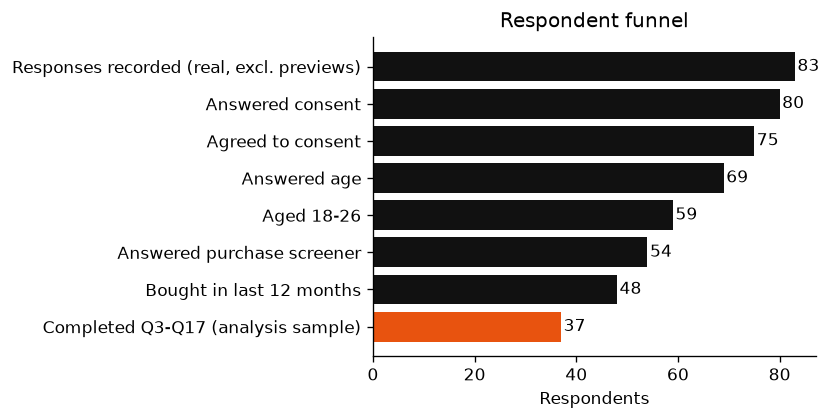

In [14]:
for c in ["own_apparel", "own_footwear", "last_brand", "gender", "social_hours", "group3", "group4"]:
    t = clean[c].value_counts(dropna=False).rename("n").to_frame()
    t["%"] = (t["n"] / t["n"].sum() * 100).round(1)
    print(f"\n{c}\n", t)

num = ["intent"] + COL["attitude"] + ["attitude_index"] + ["sneaker_" + n for n in FACTORS] + ["repeat_" + n for n in FACTORS]
print("\n", clean[num].describe().T[["count", "mean", "std", "min", "max"]].round(2))

# Figure 1: respondent funnel
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(funnel["Stage"][::-1], funnel["n"][::-1], color="#111")
ax.barh(funnel["Stage"].iloc[-1], funnel["n"].iloc[-1], color="#e8530f")
for y, v in enumerate(funnel["n"][::-1]): ax.text(v + 0.5, y, str(v), va="center")
ax.set_xlabel("Respondents"); ax.set_title("Respondent funnel")
plt.tight_layout(); plt.savefig("figs/fig1_funnel.png"); plt.show()

## C. RQ1: Ownership overlap and rival brands
**H0**: owning adidas footwear is independent of owning adidas apparel. **H1**: they are associated.
Tests: cross-tab, chi-square (Fisher's exact test when expected counts < 5), Wilson CI for the share of apparel owners who also own footwear, and the brand split of the latest sneaker purchase.

own_footwear  No  Yes  All
own_apparel               
No             6    7   13
Yes            4   20   24
All           10   27   37 

Expected counts:
 own_footwear    No    Yes
own_apparel              
No            3.51   9.49
Yes           6.49  17.51
Chi-square(1) = 3.718, p = 0.0538, Cramer's V = 0.317
Fisher exact: odds ratio = 4.29, p = 0.1178   (use this if any expected count < 5)

Apparel owners who also own adidas footwear: 20/24 = 83.3%, 95% CI [64.1%, 93.3%]

Most recent sneaker brand (all analysis sample):
              n     %
last_brand          
Nike        16  44.4
Adidas       9  25.0
Asics        5  13.9
Puma         4  11.1
Others       2   5.6
Nike vs adidas exact binomial p = 0.23

Latest brand by apparel ownership (row %):
 last_brand   Adidas  Asics  Nike  Others  Puma
own_apparel                                   
No             25.0   16.7  33.3    16.7   8.3
Yes            25.0   12.5  50.0     0.0  12.5


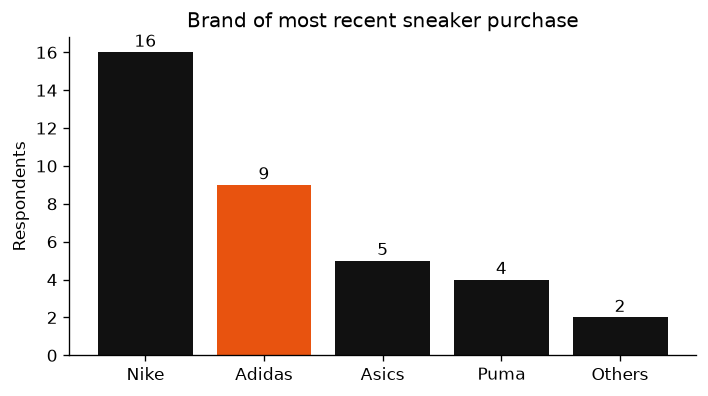

In [15]:
ct = pd.crosstab(clean["own_apparel"], clean["own_footwear"], margins=True)
print(ct, "\n")
ct2 = pd.crosstab(clean["own_apparel"], clean["own_footwear"])
chi2, p, dof, exp = stats.chi2_contingency(ct2, correction=False)
print("Expected counts:\n", pd.DataFrame(exp, index=ct2.index, columns=ct2.columns).round(2))
print(f"Chi-square({dof}) = {chi2:.3f}, p = {p:.4f}, Cramer's V = {np.sqrt(chi2 / ct2.values.sum()):.3f}")
if ct2.shape == (2, 2):
    odds, p_f = stats.fisher_exact(ct2.loc[["Yes", "No"], ["Yes", "No"]])
    print(f"Fisher exact: odds ratio = {odds:.2f}, p = {p_f:.4f}   (use this if any expected count < 5)")

app = clean[clean["own_apparel"] == "Yes"]
k, n = int((app["own_footwear"] == "Yes").sum()), len(app)
pp, lo, hi = wilson(k, n)
print(f"\nApparel owners who also own adidas footwear: {k}/{n} = {pp:.1%}, 95% CI [{lo:.1%}, {hi:.1%}]")

b = clean["last_brand"].value_counts()
bt = pd.DataFrame({"n": b, "%": (b / b.sum() * 100).round(1)})
print("\nMost recent sneaker brand (all analysis sample):\n", bt)
if {"Nike", "Adidas"} <= set(b.index):
    kn, ka = int(b["Nike"]), int(b["Adidas"])
    print("Nike vs adidas exact binomial p =", round(stats.binomtest(kn, kn + ka, 0.5).pvalue, 3))
ba = pd.crosstab(clean["own_apparel"], clean["last_brand"], normalize="index").round(3) * 100
print("\nLatest brand by apparel ownership (row %):\n", ba)

fig, ax = plt.subplots(figsize=(6, 3.4))
order = b.index
ax.bar(order, b.values, color=["#111" if x != "Adidas" else "#e8530f" for x in order])
for i, v in enumerate(b.values): ax.text(i, v + 0.3, str(v), ha="center")
ax.set_ylabel("Respondents"); ax.set_title("Brand of most recent sneaker purchase")
plt.tight_layout(); plt.savefig("figs/fig2_brand.png"); plt.show()

## D. RQ2: Which factors matter most when choosing sneakers?
**H0**: all five factors are equally important (equal mean ratings). **H1**: at least one factor is rated differently.
Main measure: Q6-Q10 (sneakers). Tests: Friedman test (repeated measures, 5 factors) with Kendall's W, then all 10 pairwise paired t-tests with Holm correction, plus one-sample t-tests against the neutral midpoint 4. Q11 repeats the same five items on purpose, so it is used as a **reliability check** (test-retest correlation, mean difference, same ranking).

Sneaker choice factors (Q6-Q10), one-sample t-tests against neutral = 4
              Factor  n  Mean    SD       95% CI  t vs 4  p vs 4  p vs 4 (Holm)  Rank
              Price 37 5.054 1.153 [4.67, 5.44]   5.559   0.000          0.000     3
     Style & design 37 5.811 1.076 [5.45, 6.17]  10.237   0.000          0.000     1
      Comfort & fit 37 5.595 1.189 [5.20, 5.99]   8.156   0.000          0.000     2
        Brand image 36 4.583 1.360 [4.12, 5.04]   2.573   0.014          0.029     4
Influencer approval 37 4.135 1.903 [3.50, 4.77]   0.432   0.668          0.668     5

Friedman test (n=36): chi2(4) = 31.43, p = 2.5e-06, Kendall's W = 0.218

Pairwise paired t-tests (Holm over 10 comparisons):
                                  Pair  n  Mean diff         95% CI      t     p  Cohen dz  p (Holm)
              Price vs Style & design 37     -0.757 [-1.20, -0.31] -3.431 0.002    -0.564     0.009
               Price vs Comfort & fit 37     -0.541 [-1.01, -0.07] -2.338 0.025    -0.384 

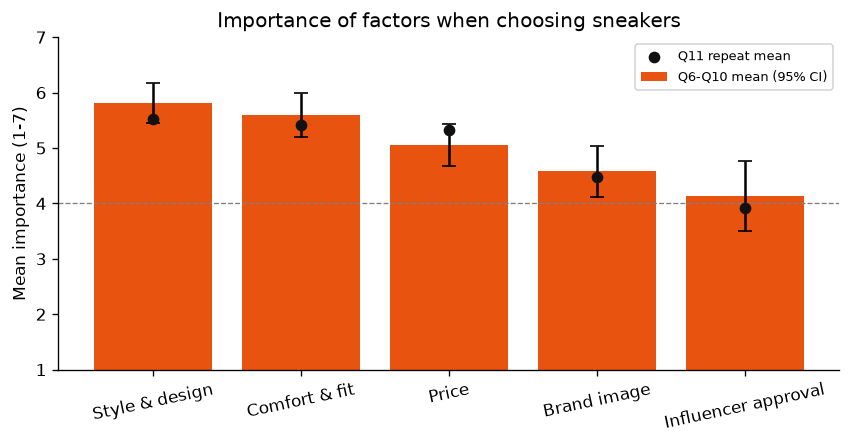

In [16]:
from itertools import combinations

def holm(pvals):
    p = np.asarray(pvals, float); m = len(p); order = p.argsort(); adj = np.empty(m); run = 0
    for rank, idx in enumerate(order):
        run = max(run, (m - rank) * p[idx]); adj[idx] = min(1, run)
    return adj

sn_cols = ["sneaker_" + n for n in FACTORS]
rows = []
for n_ in FACTORS:
    x = clean["sneaker_" + n_].dropna()
    ci = stats.t.interval(0.95, len(x) - 1, x.mean(), stats.sem(x))
    t, p = stats.ttest_1samp(x, 4)
    rows.append([n_, len(x), x.mean(), x.std(ddof=1), f"[{ci[0]:.2f}, {ci[1]:.2f}]", t, p])
rq2 = pd.DataFrame(rows, columns=["Factor", "n", "Mean", "SD", "95% CI", "t vs 4", "p vs 4"])
rq2["p vs 4 (Holm)"] = holm(rq2["p vs 4"])
rq2["Rank"] = rq2["Mean"].rank(ascending=False).astype(int)
print("Sneaker choice factors (Q6-Q10), one-sample t-tests against neutral = 4\n", rq2.round(3).to_string(index=False))

S = clean[sn_cols].dropna(); k = len(FACTORS)
fr = stats.friedmanchisquare(*[S[c] for c in sn_cols])
print(f"\nFriedman test (n={len(S)}): chi2({k-1}) = {fr.statistic:.2f}, p = {fr.pvalue:.2g}, Kendall's W = {fr.statistic/(len(S)*(k-1)):.3f}")

pw = []
for a_, b_ in combinations(FACTORS, 2):
    d_ = clean[["sneaker_" + a_, "sneaker_" + b_]].dropna()
    diff = d_.iloc[:, 0] - d_.iloc[:, 1]
    t, p = stats.ttest_rel(d_.iloc[:, 0], d_.iloc[:, 1])
    ci = stats.t.interval(0.95, len(d_) - 1, diff.mean(), stats.sem(diff))
    pw.append([a_ + " vs " + b_, len(d_), diff.mean(), f"[{ci[0]:.2f}, {ci[1]:.2f}]", t, p, diff.mean() / diff.std(ddof=1)])
pw = pd.DataFrame(pw, columns=["Pair", "n", "Mean diff", "95% CI", "t", "p", "Cohen dz"])
pw["p (Holm)"] = holm(pw["p"])
print("\nPairwise paired t-tests (Holm over 10 comparisons):\n", pw.round(3).to_string(index=False))

# Reliability check: Q11 repeats the same five items
rel = []
for n_ in FACTORS:
    d_ = clean[["sneaker_" + n_, "repeat_" + n_]].dropna()
    diff = d_.iloc[:, 0] - d_.iloc[:, 1]
    r_, p_r = stats.pearsonr(d_.iloc[:, 0], d_.iloc[:, 1])
    t, p = stats.ttest_rel(d_.iloc[:, 0], d_.iloc[:, 1])
    rel.append([n_, len(d_), d_.iloc[:, 0].mean(), d_.iloc[:, 1].mean(), diff.mean(), r_, t, p,
                (diff.abs() <= 1).mean() * 100])
rel = pd.DataFrame(rel, columns=["Factor", "n", "Mean Q6-10", "Mean Q11", "Diff", "Pearson r", "paired t", "p", "% within 1 pt"])
print("\nReliability: Q6-Q10 vs repeat Q11\n", rel.round(3).to_string(index=False))
rk6 = clean[sn_cols].mean().rank(ascending=False).values
rk11 = clean[["repeat_" + n for n in FACTORS]].mean().rank(ascending=False).values
print("Same factor ranking in Q6-10 and Q11:", bool((rk6 == rk11).all()), "| Spearman of the 5 means:", round(stats.spearmanr(clean[sn_cols].mean(), clean[["repeat_" + n for n in FACTORS]].mean()).statistic, 3))

order_ = rq2.sort_values("Mean", ascending=False)
fig, ax = plt.subplots(figsize=(7.2, 3.8))
xs = np.arange(len(order_))
err = [stats.sem(clean["sneaker_" + f].dropna()) * stats.t.ppf(.975, len(clean["sneaker_" + f].dropna()) - 1) for f in order_["Factor"]]
ax.bar(xs, order_["Mean"], yerr=err, capsize=4, color="#e8530f", label="Q6-Q10 mean (95% CI)")
ax.scatter(xs, [clean["repeat_" + f].mean() for f in order_["Factor"]], color="#111", zorder=3, label="Q11 repeat mean")
ax.axhline(4, ls="--", c="grey", lw=0.8); ax.set_xticks(xs, order_["Factor"], rotation=12)
ax.set_ylim(1, 7); ax.set_ylabel("Mean importance (1-7)"); ax.legend(fontsize=8, loc="upper right")
ax.set_title("Importance of factors when choosing sneakers")
plt.tight_layout(); plt.savefig("figs/fig3_factors.png"); plt.show()

## E. RQ3: Apparel attitude and sneaker purchase intention
**H0**: no linear association between attitude toward adidas apparel and intention to buy adidas sneakers (rho = 0). **H1**: rho differs from 0 (we expect positive).
Pearson correlation (Spearman as robustness check) and a simple regression for R-squared. 'Cannot judge' is treated as missing; the last block shows what happens if it is wrongly coded as 0.

n = 32
Pearson r = 0.550, p = 0.0011, 95% CI [0.249, 0.754]
Spearman rho = 0.493, p = 0.0041
Regression: intent = 0.731 + 0.0516 x attitude ; R-squared = 0.302 ; slope p = 0.0011
Each +10 attitude points is associated with +0.52 points of intention (1-7).
Critical |r| for p<.05 at n=32: 0.349

Sensitivity (Cannot judge coded 0, n=35): r = 0.488, p = 0.0029; mean intent = 3.77 vs 4.12 when treated as missing


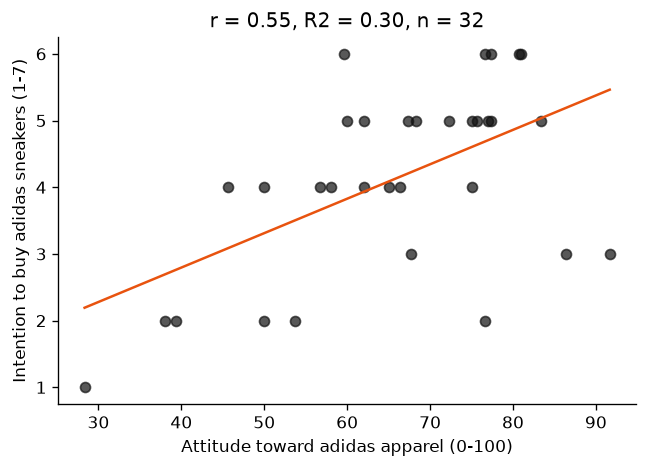

In [17]:
d = clean[["attitude_index", "intent"]].dropna()
r, p = stats.pearsonr(d["attitude_index"], d["intent"])
ci = stats.pearsonr(d["attitude_index"], d["intent"]).confidence_interval()
rho, p_s = stats.spearmanr(d["attitude_index"], d["intent"])
lr = stats.linregress(d["attitude_index"], d["intent"])
print(f"n = {len(d)}")
print(f"Pearson r = {r:.3f}, p = {p:.4f}, 95% CI [{ci.low:.3f}, {ci.high:.3f}]")
print(f"Spearman rho = {rho:.3f}, p = {p_s:.4f}")
print(f"Regression: intent = {lr.intercept:.3f} + {lr.slope:.4f} x attitude ; R-squared = {lr.rvalue**2:.3f} ; slope p = {lr.pvalue:.4f}")
print(f"Each +10 attitude points is associated with {lr.slope*10:+.2f} points of intention (1-7).")
print(f"Critical |r| for p<.05 at n={len(d)}: {stats.t.ppf(.975, len(d)-2)/np.sqrt(len(d)-2+stats.t.ppf(.975, len(d)-2)**2):.3f}")

# Sensitivity: 'Cannot judge' coded 0 (what the slides did)
d0 = clean[["attitude_index", "intent_raw"]].dropna()
r0, p0 = stats.pearsonr(d0["attitude_index"], d0["intent_raw"])
print(f"\nSensitivity (Cannot judge coded 0, n={len(d0)}): r = {r0:.3f}, p = {p0:.4f}; mean intent = {d0['intent_raw'].mean():.2f} vs {d['intent'].mean():.2f} when treated as missing")

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.scatter(d["attitude_index"], d["intent"], color="#111", alpha=0.7)
xs = np.linspace(d["attitude_index"].min(), d["attitude_index"].max(), 50)
ax.plot(xs, lr.intercept + lr.slope * xs, color="#e8530f")
ax.set_xlabel("Attitude toward adidas apparel (0-100)"); ax.set_ylabel("Intention to buy adidas sneakers (1-7)")
ax.set_title(f"r = {r:.2f}, R2 = {lr.rvalue**2:.2f}, n = {len(d)}")
plt.tight_layout(); plt.savefig("figs/fig4_attitude_intent.png"); plt.show()

## F. RQ4: Purchase intention by ownership group
**H0**: mean intention is equal across the ownership groups. **H1**: at least one group mean differs.
One-way ANOVA with Levene's test for equal variances, eta-squared, Tukey HSD post-hoc test, and Kruskal-Wallis as a robustness check. The three mutually exclusive groups are *Footwear owner*, *Apparel only* and *Neither*; the four-group split is shown descriptively.

                count  mean   std
group3                           
Apparel only        4  3.75  1.71
Footwear owner     25   4.4  1.22
Neither             4   2.0  1.41 

Four-group split (descriptive):
                     count  mean   std
group4                               
Apparel + footwear     18   4.5  1.04
Apparel only            4  3.75  1.71
Footwear only           7  4.14  1.68
Neither                 4   2.0  1.41 

Levene W = 0.192, p = 0.8259
ANOVA F(2, 30) = 5.976, p = 0.0065, eta-squared = 0.285
Kruskal-Wallis H = 7.337, p = 0.0255

Tukey HSD p-values (rows/cols in order): ['Apparel only', 'Footwear owner', 'Neither']
                Apparel only  Footwear owner  Neither
Apparel only           1.000           0.627    0.155
Footwear owner         0.627           1.000    0.005
Neither                0.155           0.005    1.000


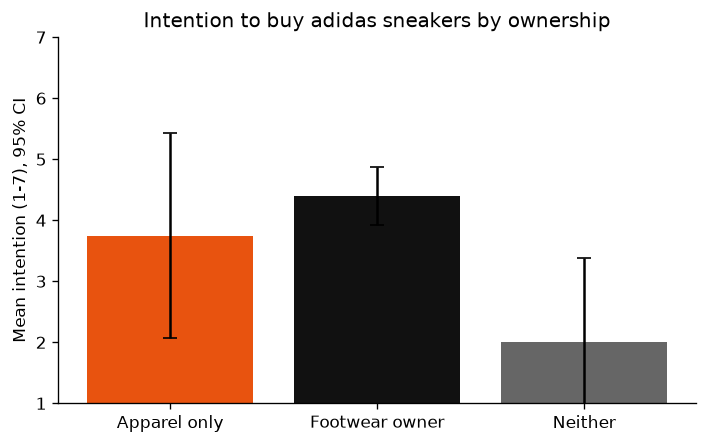

In [18]:
d = clean[["group3", "intent"]].dropna()
g = d.groupby("group3")["intent"].agg(["count", "mean", "std"]).round(2)
print(g, "\n")
print("Four-group split (descriptive):\n", clean.dropna(subset=["intent"]).groupby("group4")["intent"].agg(["count", "mean", "std"]).round(2), "\n")

samples = [x["intent"].values for _, x in d.groupby("group3") if len(x) >= 2]
names = [k for k, x in d.groupby("group3") if len(x) >= 2]
if len(samples) >= 2:
    lev = stats.levene(*samples)
    F, p = stats.f_oneway(*samples)
    grand = d["intent"].mean()
    ss_b = sum(len(s) * (s.mean() - grand) ** 2 for s in samples)
    ss_t = ((d["intent"] - grand) ** 2).sum()
    print(f"Levene W = {lev.statistic:.3f}, p = {lev.pvalue:.4f}")
    print(f"ANOVA F({len(samples)-1}, {len(d)-len(samples)}) = {F:.3f}, p = {p:.4f}, eta-squared = {ss_b/ss_t:.3f}")
    kw = stats.kruskal(*samples); print(f"Kruskal-Wallis H = {kw.statistic:.3f}, p = {kw.pvalue:.4f}")
    th = stats.tukey_hsd(*samples)
    print("\nTukey HSD p-values (rows/cols in order):", names)
    print(pd.DataFrame(th.pvalue, index=names, columns=names).round(3))
else:
    print("Fewer than two groups have n >= 2: merge groups before running ANOVA.")

fig, ax = plt.subplots(figsize=(6, 3.8))
means = d.groupby("group3")["intent"].mean(); sems = d.groupby("group3")["intent"].sem()
ax.bar(means.index, means.values, yerr=1.96 * sems.fillna(0).values, capsize=4, color=["#e8530f", "#111", "#666"][:len(means)])
ax.set_ylim(1, 7); ax.set_ylabel("Mean intention (1-7), 95% CI"); ax.set_title("Intention to buy adidas sneakers by ownership")
plt.tight_layout(); plt.savefig("figs/fig5_intent_groups.png"); plt.show()

## G. Notes for the report
* The effective sample is small (n of about 39), so non-significant results mean *no detectable* effect, not *no effect*; report confidence intervals and effect sizes.
* Respondents are a convenience sample (mostly men, heavy social-media users): results do not generalise to all 18-26 year olds.
* Intention is self-reported and is not the same as purchases.
* Q15 'Cannot judge' is treated as missing; attitude items were collected as 0-100 sliders rather than the 7-point scale first planned.